<a href="https://colab.research.google.com/github/BradKruithof/Brad_INFO4670_Fall2026/blob/main/Copy_of_INFO4670_Week3_Assignment1_Template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1 — Making Sense of Northgate through Visualization
**INFO 4670 · Data Analysis and Knowledge Discovery**  ·  **Due: Sunday, 11:59 PM**

**Name:** Brad Kruithof   **Date:** 9/2/2026

**The situation.** The Provost's question stands: *which students are struggling, and can we see it earlier?* This week you answer it the way analysts do — not by reading rows, but by drawing the data. Every chart below is built by **adapting code from the Guided notebook**; the intellectual work is choosing the right chart and reading it honestly.

**For every chart you make, you must:**
1. **Choose** the chart type that fits the variable(s) and the question.
2. **Build** it in Colab from the Northgate files.
3. **Label** it fully — title, axis labels, and units/legend. *An unlabeled chart is an unfinished chart.*
4. **Write a STAR story** underneath it — Scope · Track · Articulate · Respond (defined on the Concepts deck).

**How to work:** run Setup and Load first. Then, for each question, copy the closest cell from the Guided notebook into the empty cell, adapt it, and fill in the STAR cell below it.

**Submit:** push this notebook to GitHub and submit the **GitHub link** in Canvas. (See the setup doc: *Colab_GitHub_Setup_INFO4670_Fall2026*.)

## Setup — run this first (you don't need to change it)

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Northgate house style (optional, but keeps your charts consistent)
NAVY = "#22303A"
RUST = "#C0562F"
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"]   = (8, 5)
plt.rcParams["axes.titlesize"]   = 13
plt.rcParams["axes.titleweight"] = "bold"

## Load the data — run this, then look before you plot

In [39]:
# STEP 1 — get the data into this notebook. Pick ONE option, then run.

import pandas as pd # Added this line

DATA_DIR = "."   # OPTION 2 (default) · drag the 3 CSVs into the file panel on the left

# OPTION 1 · read from Google Drive — uncomment and edit the path:
# from google.colab import drive
# drive.mount("/content/drive")
# DATA_DIR = "/content/drive/MyDrive/.../Data"

import os
students = pd.read_csv(os.path.join(DATA_DIR, "student_records.csv"))
weekly   = pd.read_csv(os.path.join(DATA_DIR, "weekly_activity.csv"))
students.head()

,student_id,major,age,housing,commute_miles,work_hours_per_week,advisor_meetings,credits_attempted,final_gpa,study_hours_reported,enrollment_date,dropped_out
0,NU-101508,Data Science,27,Off-Campus,7.6,15,1,81,1.86,NaN,2023-09-13,1
1,NU-102438,Learning Technologies,25,With Family,14.3,35,1,100,2.06,9.5,2023-10-19,0
2,NU-102385,Learning Technologies,26,With Family,3.4,18,9,77,3.41,19.1,11/16/2022,0
3,NU-100767,Cyber Security,22,On-Campus,23.7,40,1,65,1.73,8.1,2024-05-03,0
4,NU-106054,Information Technology,21,Off-Campus,2.3,20,4,59,2.37,6.6,10/24/2022,0


In [40]:
# how many rows, which columns, what types?
students.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2027 entries, 0 to 2026
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   student_id            2027 non-null   object 
 1   major                 2027 non-null   object 
 2   age                   2027 non-null   int64  
 3   housing               2027 non-null   object 
 4   commute_miles         2027 non-null   float64
 5   work_hours_per_week   2027 non-null   int64  
 6   advisor_meetings      2027 non-null   int64  
 7   credits_attempted     2027 non-null   int64  
 8   final_gpa             2027 non-null   float64
 9   study_hours_reported  1772 non-null   float64
 10  enrollment_date       2027 non-null   object 
 11  dropped_out           2027 non-null   int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 190.2+ KB


# Part A — Guided questions
Build **one chart per question**. Each maps to one chart family from this week. Copy the closest Guided-notebook cell, adapt it, label it, then write its STAR story.

### Q1 · One quantitative variable
**How many hours per week do Northgate students work?** Describe what's typical, how spread out it is, and whether anyone stands apart.
→ *histogram* (add a *box plot* if it helps). Column: `work_hours_per_week` (from `students`).

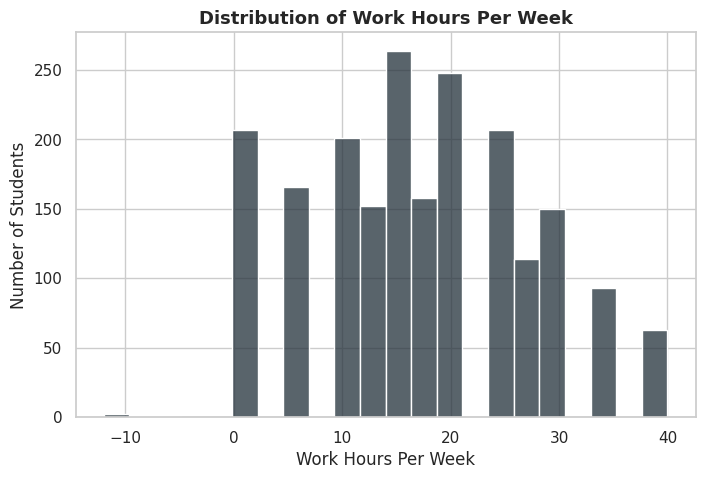

In [41]:

fig, ax = plt.subplots()
sns.histplot(data=students, x="work_hours_per_week", color=NAVY, ax=ax)
ax.set_title("Distribution of Work Hours Per Week")
ax.set_xlabel("Work Hours Per Week")
ax.set_ylabel("Number of Students")
plt.show()

**STAR story — Q1** *(write in your own words)*

- **Scope —** what does this chart show? (which column(s), which students)
- **Track —** which question are you answering?
- **Articulate —** what does the chart actually say? (typical value, spread, shape, comparison, or trend)
- **Respond —** anything odd or unexpected? what would you look at next? *(note it — you don't fix it this week)*

This chart shows us the amount of how many students are working to how many hours. Most students are working from 10-20 hours a week. The chart is skewed right as we see the numbers of students dropping to higher numbers of hours worked. What is strange is there is a very small number of students working -10 hours. This data seems to be incorrect and should be investigated thoroughly.

### Q2 · One categorical variable
**How does enrollment compare across majors?**
→ *sorted bar chart*. Column: `major` (from `students`).

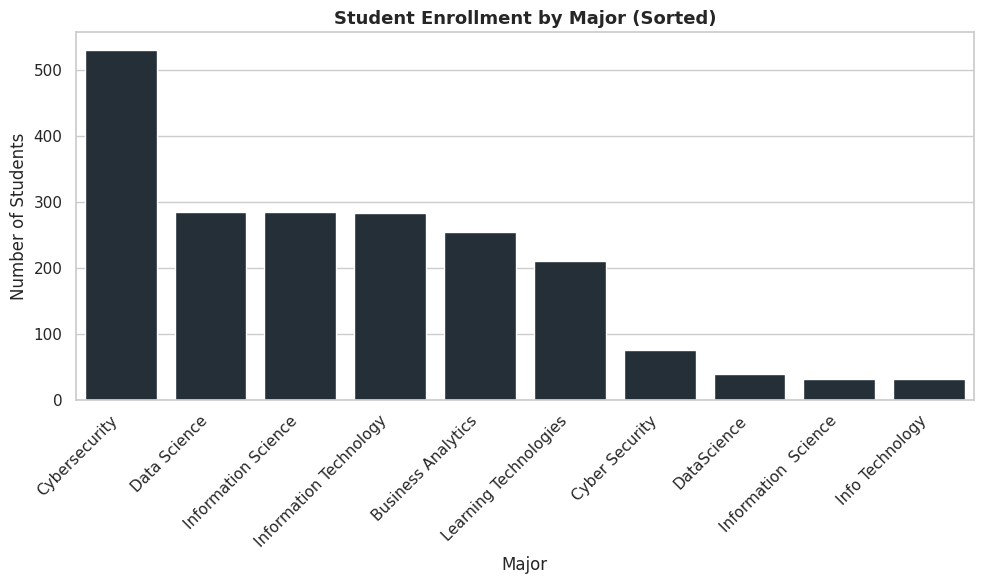

In [42]:
major_counts = students['major'].value_counts().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=major_counts.index, y=major_counts.values, color=NAVY, ax=ax)
ax.set_title("Student Enrollment by Major (Sorted)")
ax.set_xlabel("Major")
ax.set_ylabel("Number of Students")
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.tight_layout()
plt.show()

**STAR story — Q1** *(write in your own words)*

- **Scope —** what does this chart show? (which column(s), which students)
- **Track —** which question are you answering?
- **Articulate —** what does the chart actually say? (typical value, spread, shape, comparison, or trend)
- **Respond —** anything odd or unexpected? what would you look at next? *(note it — you don't fix it this week)*

This chart highlights the right skewedness of the enrollment across majors. There is a high number of Cybersecurity ranging to over 500 students enrolled. We also see similiar number of enrollment such as the "information" majors. This chart tells us the variation of student interest in specific majors. Most students chose Cybersecurity out of any other major. What is odd is there seems to be an error. There is another "Cyber Security, DataScience, Information Science, and Info Technology" majors. Those majors have a low amount of students signed up. It looks to be there is another set of majors with the same title but less students are interested.

### Q3 · A quantity, split by category
**Does final GPA differ across majors?** Read the exceptions, not just the boxes.
→ *box plot per major*. Columns: `final_gpa` and `major` (from `students`).

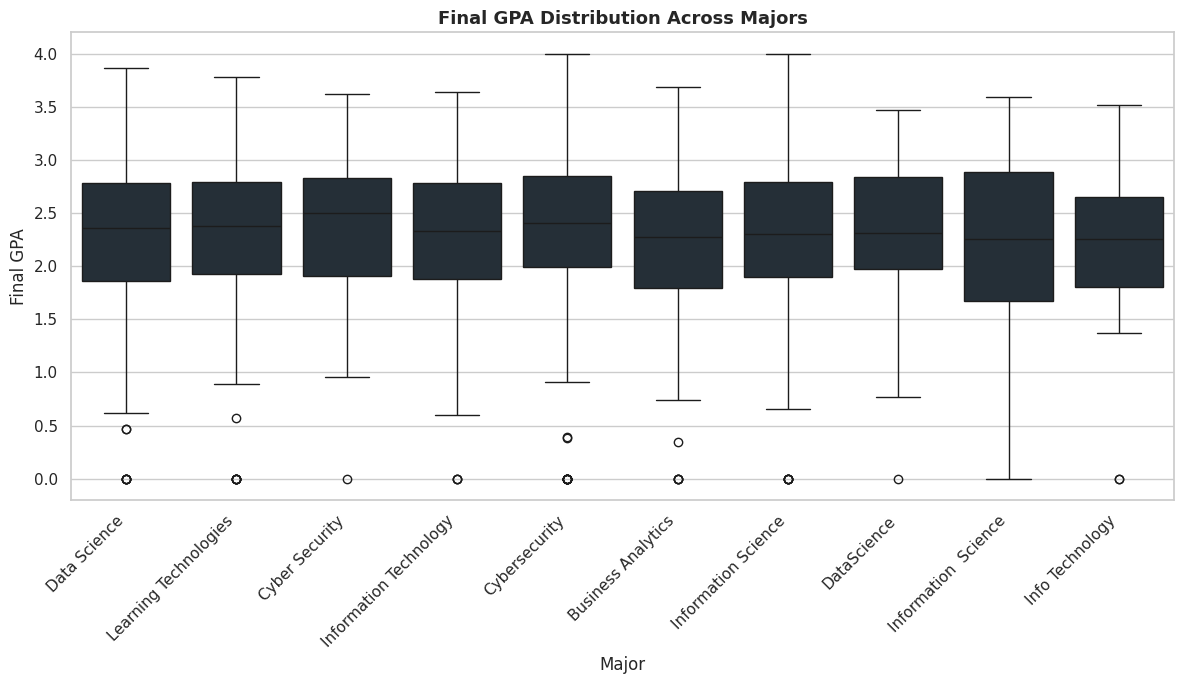

In [43]:
fig, ax = plt.subplots(figsize=(12, 7))
sns.boxplot(data=students, x="major", y="final_gpa", color=NAVY, ax=ax)
ax.set_title("Final GPA Distribution Across Majors")
ax.set_xlabel("Major")
ax.set_ylabel("Final GPA")
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.tight_layout()
plt.show()

**STAR story — Q3** *(write in your own words)*

- **Scope —** what does this chart show? (which column(s), which students)
- **Track —** which question are you answering?
- **Articulate —** what does the chart actually say? (typical value, spread, shape, comparison, or trend)
- **Respond —** anything odd or unexpected? what would you look at next? *(note it — you don't fix it this week)*

We see a symmetric build of GPA across all the majors given. There are a few outliers however that highlight a few students have actually gotten a 0 GPA. Every major represented in this chart reveals there 0.0-0.5 GPA's that stand out from their main distributions. These GPA's should still be contributed to the overall box frequencies. What is unexpected is Information Science has a minimum frequency line that starts at 0.0 GPA. This distribution is rather interesting compared to the other majors.

### Q4 · Two quantitative variables
**Is there a relationship between how far students commute and their final GPA?** Remember: *association is not causation.*
→ *scatterplot with a trend line*. Columns: `commute_miles` and `final_gpa` (from `students`).

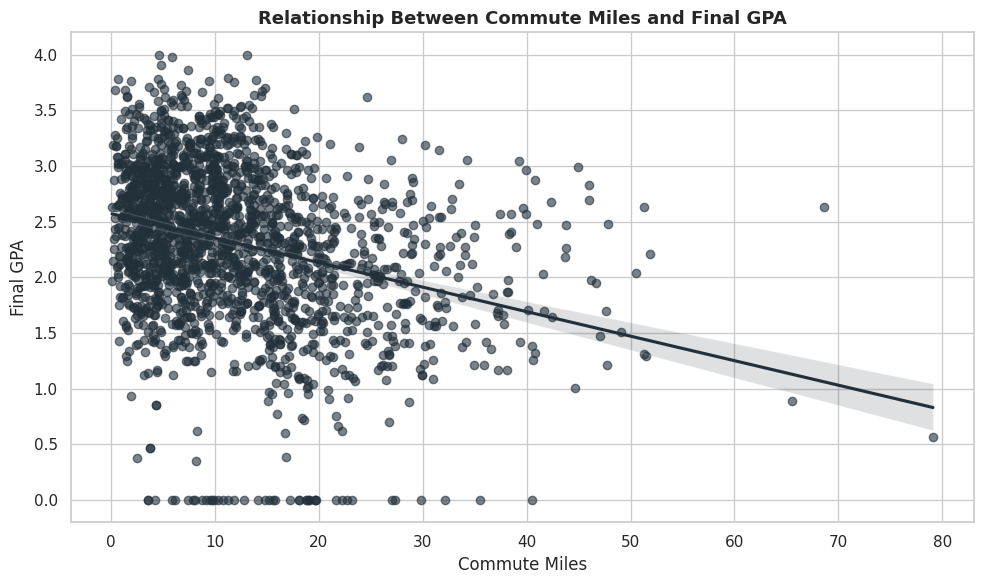

In [44]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(data=students, x="commute_miles", y="final_gpa", color=NAVY, ax=ax, scatter_kws={'alpha':0.6})
ax.set_title("Relationship Between Commute Miles and Final GPA")
ax.set_xlabel("Commute Miles")
ax.set_ylabel("Final GPA")
plt.tight_layout()
plt.show()

**STAR story — Q4** *(write in your own words)*

- **Scope —** what does this chart show? (which column(s), which students)
- **Track —** which question are you answering?
- **Articulate —** what does the chart actually say? (typical value, spread, shape, comparison, or trend)
- **Respond —** anything odd or unexpected? what would you look at next? *(note it — you don't fix it this week)*

We see in the chart that most students commute within 20 miles. This however does not have a say in their final GPA. We see a overwhelmingly distribution of Final GPA dots scattered from 0.0-4.0. Most of the GPA we see with students commuting within 20 miles is anywhere from 1.5-3.0 GPA. This however does not have a final say in what students GPA is. What is interesting is we see a student commuting from over 60 miles and they have a GPA higher than most students. This comes to show commuting distance does not relate to Final GPA.

### Q5 · Over time
**How does student engagement change across the semester?**
→ *line chart* of average weekly activity. Use the `weekly` table: `week` and `minutes_active` (you'll need to average by week first — see the Guided notebook).

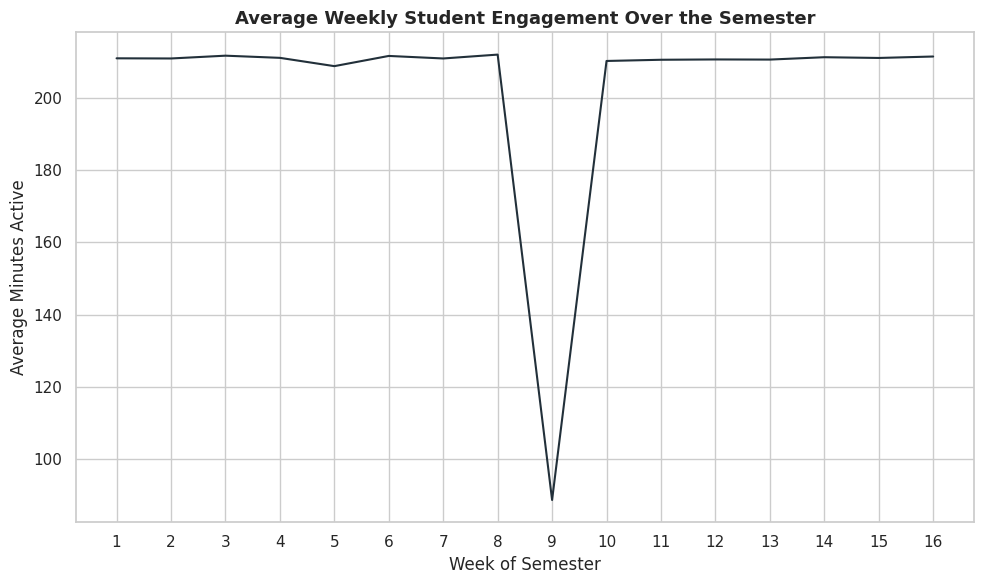

In [45]:
avg_weekly_activity = weekly.groupby('week')['minutes_active'].mean().reset_index()

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(data=avg_weekly_activity, x="week", y="minutes_active", color=NAVY, ax=ax)
ax.set_title("Average Weekly Student Engagement Over the Semester")
ax.set_xlabel("Week of Semester")
ax.set_ylabel("Average Minutes Active")
plt.xticks(avg_weekly_activity['week'].unique()) # Ensure all weeks are shown on x-axis
plt.tight_layout()
plt.show()

There is a huge decline of average minutes active by week 9. This overwhelming dip in numbers can highlight the busyness of student life by week 9. From weeks 1-8 and weeks 10-16 there is a steady line of minitues active for students. This chart comes to say that there is a huge amount of trend that comes to student life by week 9 that ultimately kills average minutes active. There is an interesting dip at week 5 that should be studied. The dip isn't as severe as week 9 but shows a common trend of minutes decline.

**STAR story — Q5** *(write in your own words)*

- **Scope —** what does this chart show? (which column(s), which students)
- **Track —** which question are you answering?
- **Articulate —** what does the chart actually say? (typical value, spread, shape, comparison, or trend)
- **Respond —** anything odd or unexpected? what would you look at next? *(note it — you don't fix it this week)*

# Part B — Your own question (open)
Pose **one question of your own** about the Northgate students, choose the chart that answers it, build it, label it, and write its STAR story. Going beyond Part A is rewarded — a per-student line chart, a violin plot, or a chart of a messier column are all fair game.

**Your question:** Does GPA differ based off of Student Commute Distance?



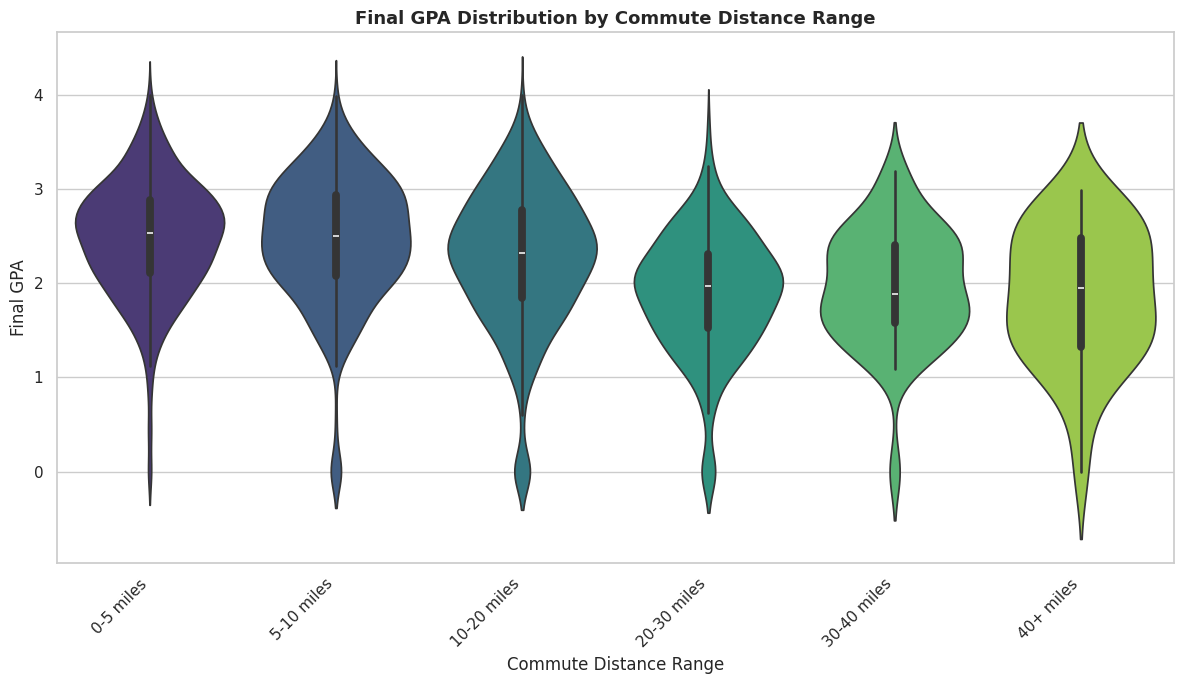

In [46]:
bins = [0, 5, 10, 20, 30, 40, 80] # Define bins for commute miles
labels = ['0-5 miles', '5-10 miles', '10-20 miles', '20-30 miles', '30-40 miles', '40+ miles']
students['commute_range'] = pd.cut(students['commute_miles'], bins=bins, labels=labels, right=False)

fig, ax = plt.subplots(figsize=(12, 7))
sns.violinplot(data=students, x="commute_range", y="final_gpa", hue="commute_range", palette="viridis", ax=ax, legend=False)
ax.set_title("Final GPA Distribution by Commute Distance Range")
ax.set_xlabel("Commute Distance Range")
ax.set_ylabel("Final GPA")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**STAR story — Part B** *(write in your own words)*

- **Scope —** what does this chart show? (which column(s), which students)
- **Track —** which question are you answering?
- **Articulate —** what does the chart actually say? (typical value, spread, shape, comparison, or trend)
- **Respond —** anything odd or unexpected? what would you look at next? *(note it — you don't fix it this week)*

We see GPA does not ultimately differ based off of student commute distance. GPA is not dependant on the commute distance. GPA seems to be evenly distributed across all distances. However we do see a small trend of students falling under the 1.0 GPA mark. This comes to show that no matter the distance, GPA is of its own entity.

# Before you submit — checklist
- [ ] The notebook **runs top to bottom** with no errors (Runtime → Restart and run all).
- [ ] All **6 charts** are present, each with a title, labeled axes, and units/legend where needed.
- [ ] Each chart has a **complete STAR story**, including any exceptions you spotted.
- [ ] Part B question is written in and answered.
- [ ] Pushed to **GitHub**, and the **GitHub link** is submitted in Canvas.

**Rubric (70 pts):** chart choice 10 · correct build 20 · labeling 10 · STAR reading 18 · Part B question 4 · submission & professionalism 8.